In [1]:
# M24CA1L306 Data Science Lab - Lab Exercise #23
# Student: Abhinav | MAC25MCA-2002 | S3 MCA (2025-27)
# Dataset: <PLACEHOLDER - replace with Air Quality CSV filename>
#          PLACEHOLDER: adjust column names below to match your file
# Task: DBSCAN Clustering on Air Quality Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors


In [2]:

# ─────────────────────────────────────────────
# Load dataset
# ─────────────────────────────────────────────
df = pd.read_csv("../Datasets/Air_Quality.csv")

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nMissing values:\n", df.isnull().sum())


Shape: (9471, 17)
Columns: ['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Unnamed: 15', 'Unnamed: 16']

Missing values:
 Date              114
Time              114
CO(GT)            114
PT08.S1(CO)       114
NMHC(GT)          114
C6H6(GT)          114
PT08.S2(NMHC)     114
NOx(GT)           114
PT08.S3(NOx)      114
NO2(GT)           114
PT08.S4(NO2)      114
PT08.S5(O3)       114
T                 114
RH                114
AH                114
Unnamed: 15      9471
Unnamed: 16      9471
dtype: int64


In [3]:
# Keep only numeric sensor columns (drop Date/Time and empty columns)
df = df.drop(columns=["Date", "Time"], errors="ignore")
df = df.apply(pd.to_numeric, errors="coerce")
df = df.dropna(axis=1, how="all")

# -200 is the dataset's "missing value" marker; replace and fill with median
df = df.replace(-200, np.nan).replace([np.inf, -np.inf], np.nan)
df = df.fillna(df.median())

X = df.values

In [4]:
# ── 2. Scale + PCA ────────────────────────────────────
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print(f"Data shape: {X_scaled.shape} | Explained variance: {pca.explained_variance_ratio_.sum():.2%}")


Data shape: (9471, 13) | Explained variance: 70.41%


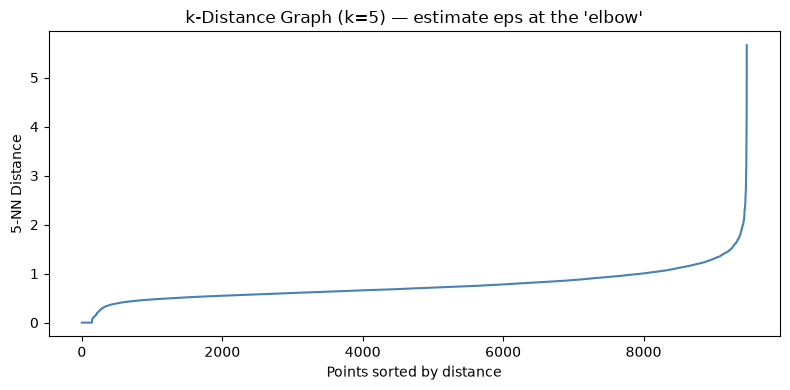

In [5]:
# ── 3. Estimate eps via k-distance plot ───────────────
nbrs = NearestNeighbors(n_neighbors=5).fit(X_scaled)
distances, _ = nbrs.kneighbors(X_scaled)
distances = np.sort(distances[:, 4])

plt.figure(figsize=(8, 4))
plt.plot(distances, color="steelblue")
plt.xlabel("Points sorted by distance")
plt.ylabel("5-NN Distance")
plt.title("k-Distance Graph (k=5) — estimate eps at the 'elbow'")
plt.tight_layout()
plt.savefig("../Outputs/lab-23_Output/lab23_kdistance.png", dpi=100)
plt.show()

In [6]:
# ── 4. DBSCAN Clustering (main run) ───────────────────
eps = 1.5          # read from k-distance elbow; 0.5 fragments the data
min_samples = 5

db = DBSCAN(eps=eps, min_samples=min_samples)
labels = db.fit_predict(X_scaled)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise    = (labels == -1).sum()
core_mask  = np.zeros(len(labels), dtype=bool)
core_mask[db.core_sample_indices_] = True
border_mask = (~core_mask) & (labels != -1)

print(f"Q1: Clusters: {n_clusters} | Core: {core_mask.sum()} | "
      f"Border: {border_mask.sum()} | Noise: {n_noise} ({n_noise/len(labels):.1%})")

mask = labels != -1
if n_clusters > 1 and mask.sum() > 1:
    sil = silhouette_score(X_scaled[mask], labels[mask])
    print(f"Q2: Silhouette (no noise): {sil:.4f}")

Q1: Clusters: 2 | Core: 9244 | Border: 131 | Noise: 96 (1.0%)
Q2: Silhouette (no noise): 0.3083


In [7]:
# Silhouette score (excluding noise)
if n_clusters > 1:
    mask = labels != -1
    sil = silhouette_score(X_scaled[mask], labels[mask])
    print(f"Silhouette Score (no noise): {sil:.4f}")

Silhouette Score (no noise): 0.3083


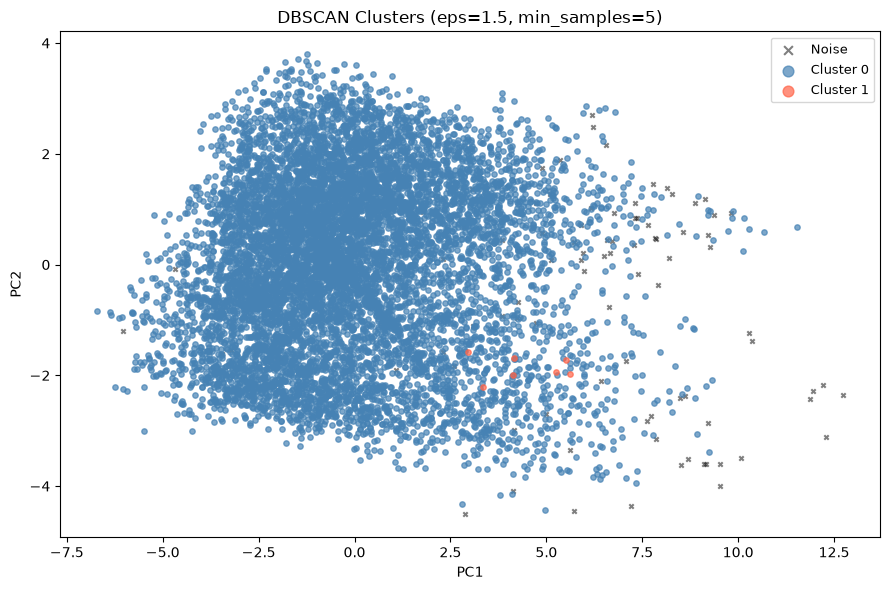

In [8]:
# ── Visualization ─────────────────────────────────────
plt.figure(figsize=(9, 6))

# Noise first (so clusters draw on top)
noise_mask = labels == -1
plt.scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1],
            c="black", marker="x", s=10, alpha=0.5, label="Noise")

# Each cluster gets a distinct named color
cluster_mask = labels != -1
colors = {0: "steelblue", 1: "tomato"}
for cluster_id in sorted(set(labels[cluster_mask])):
    mask = labels == cluster_id
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                c=colors[cluster_id], s=15, alpha=0.7,
                label=f"Cluster {cluster_id}")

plt.title(f"DBSCAN Clusters (eps={eps}, min_samples={min_samples})")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.legend(markerscale=2, fontsize=9, loc="best")
plt.tight_layout()
plt.savefig("../Outputs/lab-23_Output/lab23_clusters_default.png", dpi=100)
plt.show()

In [9]:
# ── Q4: Noise point interpretation ─────────────────────
noise_mask = labels == -1
noise_pts = df.iloc[noise_mask]

# Compare noise vs overall as ratios — much clearer than raw tables
comparison = pd.DataFrame({
    "noise_mean": noise_pts.mean(),
    "overall_mean": df.mean(),
})
comparison["ratio"] = comparison["noise_mean"] / comparison["overall_mean"]
comparison = comparison.sort_values("ratio", ascending=False)

print(f"Noise points: {noise_mask.sum()} ({noise_mask.mean():.1%})\n")
print(comparison.round(2))

Noise points: 96 (1.0%)

               noise_mean  overall_mean  ratio
C6H6(GT)            28.76          9.99   2.88
CO(GT)               5.48          2.09   2.63
NOx(GT)            582.60        234.51   2.48
NMHC(GT)           340.93        156.64   2.18
PT08.S5(O3)       1838.55       1019.87   1.80
PT08.S2(NMHC)     1490.64        937.63   1.59
NO2(GT)            171.16        112.33   1.52
PT08.S1(CO)       1547.73       1097.97   1.41
PT08.S4(NO2)      1967.33       1456.61   1.35
RH                  50.06         49.25   1.02
AH                   0.90          1.02   0.88
T                   16.08         18.29   0.88
PT08.S3(NOx)       662.76        834.00   0.79


   eps | Clusters |  Noise |   Silhouette
----------------------------------------
   0.3 |        9 |   9127 |       0.4291
   0.5 |      160 |   7219 |       0.1795
   1.0 |       27 |    873 |      -0.1449
   1.5 |        2 |     96 |       0.3083
   2.0 |        2 |     26 |       0.6394


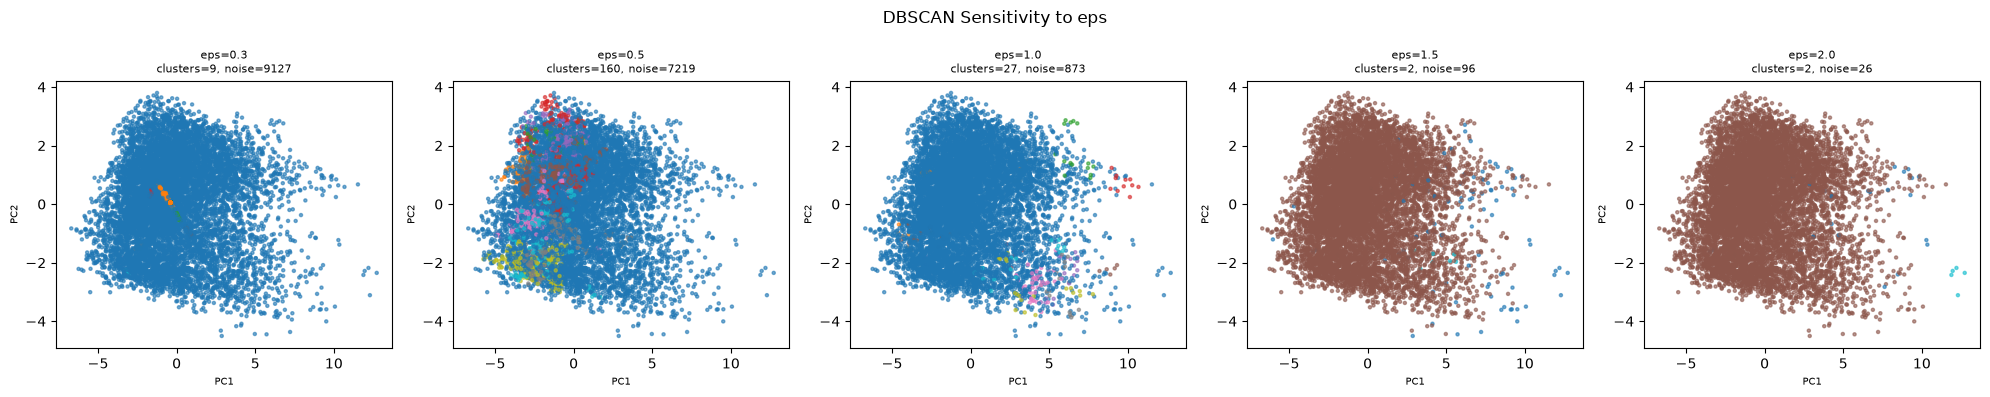

In [10]:
# ── 5. Parameter Sensitivity (eps sweep) ──────────────
eps_values = [0.3, 0.5, 1.0, 1.5, 2.0]
results = []

for e in eps_values:
    lbl = DBSCAN(eps=e, min_samples=min_samples).fit_predict(X_scaled)
    nc = len(set(lbl)) - (1 if -1 in lbl else 0)
    nn = (lbl == -1).sum()
    mask = lbl != -1
    sil = silhouette_score(X_scaled[mask], lbl[mask]) if nc > 1 and mask.sum() > 1 else np.nan
    results.append((e, nc, nn, sil))

print(f"{'eps':>6} | {'Clusters':>8} | {'Noise':>6} | {'Silhouette':>12}")
print("-" * 40)
for e, nc, nn, sil in results:
    print(f"{e:>6.1f} | {nc:>8} | {nn:>6} | {sil:>12.4f}")

# Side-by-side cluster plots
fig, axes = plt.subplots(1, len(eps_values), figsize=(20, 4))
for ax, e in zip(axes, eps_values):
    lbl = DBSCAN(eps=e, min_samples=min_samples).fit_predict(X_scaled)
    ax.scatter(X_pca[:, 0], X_pca[:, 1], c=lbl, cmap="tab10", s=5, alpha=0.6)
    nc = len(set(lbl)) - (1 if -1 in lbl else 0)
    ax.set_title(f"eps={e}\nclusters={nc}, noise={(lbl==-1).sum()}", fontsize=8)
    ax.set_xlabel("PC1", fontsize=7); ax.set_ylabel("PC2", fontsize=7)
plt.suptitle("DBSCAN Sensitivity to eps")
plt.tight_layout()
plt.savefig("../Outputs/lab-23_Output/lab23_eps_sensitivity.png", dpi=100)
plt.show()

In [11]:
# ── 6. Noise Point Analysis ───────────────────────────
noise_mask = labels == -1
print(f"Total noise points: {noise_mask.sum()} ({noise_mask.mean():.1%})")
print("\nNoise point stats:\n", df[noise_mask].describe().round(2))
print("\nOverall dataset stats:\n", df.describe().round(2))

Total noise points: 96 (1.0%)

Noise point stats:
        CO(GT)  PT08.S1(CO)  NMHC(GT)  C6H6(GT)  PT08.S2(NMHC)  NOx(GT)  \
count   96.00        96.00     96.00     96.00          96.00    96.00   
mean     5.48      1547.73    340.93     28.76        1490.64   582.60   
std      2.44       296.31    286.28     11.76         310.60   393.80   
min      0.30       708.00    150.00      0.50         437.00    93.00   
25%      3.65      1315.75    150.00     20.78        1317.75   305.75   
50%      5.60      1567.50    150.00     29.50        1539.50   388.50   
75%      6.72      1771.00    505.25     35.95        1686.00   883.50   
max     11.90      2040.00   1189.00     63.70        2214.00  1479.00   

       PT08.S3(NOx)  NO2(GT)  PT08.S4(NO2)  PT08.S5(O3)      T     RH     AH  
count         96.00    96.00         96.00        96.00  96.00  96.00  96.00  
mean         662.76   171.16       1967.33      1838.55  16.08  50.06   0.90  
std          449.05    61.46        461.68   